In [1]:
import pandas as pd
import time

from pytrends.request import TrendReq
from pytrends.exceptions import TooManyRequestsError
from requests.exceptions import ReadTimeout, ConnectionError

# Study period
START_DATE = "2021-06-01"
END_DATE = "2026-05-06"

# Keywords of interest
KEYWORDS = ["Bitcoin", "Ethereum"]

# Windowing settings
WINDOW_DAYS = 90
OVERLAP_DAYS = 30

# Retry settings
MAX_RETRIES = 5
INITIAL_WAIT_SECONDS = 30

pytrends = TrendReq(hl="en-US", tz=0)

In [2]:
# Build a list of (start, end) date windows across the full study period.
# Each new window starts OVERLAP_DAYS before the previous one ended,
# so consecutive windows share a block of dates that can later be used for rescaling.

start_date = pd.to_datetime(START_DATE)
end_date = pd.to_datetime(END_DATE)

windows = []
current_start = start_date

while current_start < end_date:
    current_end = min(current_start + pd.Timedelta(days=WINDOW_DAYS), end_date)
    windows.append((current_start, current_end))

    # Stop once we have reached the final date, to avoid an infinite loop
    if current_end >= end_date:
        break

    current_start = current_end - pd.Timedelta(days=OVERLAP_DAYS)

print(f"Created {len(windows)} windows")
for w_start, w_end in windows:
    print(w_start.date(), "->", w_end.date())

Created 30 windows
2021-06-01 -> 2021-08-30
2021-07-31 -> 2021-10-29
2021-09-29 -> 2021-12-28
2021-11-28 -> 2022-02-26
2022-01-27 -> 2022-04-27
2022-03-28 -> 2022-06-26
2022-05-27 -> 2022-08-25
2022-07-26 -> 2022-10-24
2022-09-24 -> 2022-12-23
2022-11-23 -> 2023-02-21
2023-01-22 -> 2023-04-22
2023-03-23 -> 2023-06-21
2023-05-22 -> 2023-08-20
2023-07-21 -> 2023-10-19
2023-09-19 -> 2023-12-18
2023-11-18 -> 2024-02-16
2024-01-17 -> 2024-04-16
2024-03-17 -> 2024-06-15
2024-05-16 -> 2024-08-14
2024-07-15 -> 2024-10-13
2024-09-13 -> 2024-12-12
2024-11-12 -> 2025-02-10
2025-01-11 -> 2025-04-11
2025-03-12 -> 2025-06-10
2025-05-11 -> 2025-08-09
2025-07-10 -> 2025-10-08
2025-09-08 -> 2025-12-07
2025-11-07 -> 2026-02-05
2026-01-06 -> 2026-04-06
2026-03-07 -> 2026-05-06


In [3]:
# Download Google Trends data for each window, retrying on rate limits or timeouts.
# Wait time increases after each failed attempt.

raw_windows = []

for i, (w_start, w_end) in enumerate(windows):
    start_str = w_start.strftime("%Y-%m-%d")
    end_str = w_end.strftime("%Y-%m-%d")

    print(f"Window {i + 1}/{len(windows)}: {start_str} to {end_str}")

    attempt = 0
    wait_seconds = INITIAL_WAIT_SECONDS

    while attempt < MAX_RETRIES:
        try:
            pytrends.build_payload(KEYWORDS, timeframe=f"{start_str} {end_str}")
            data = pytrends.interest_over_time()

            if not data.empty:
                data = data.drop(columns=["isPartial"], errors="ignore")
                raw_windows.append(data)

            time.sleep(20)  # brief pause between successful requests
            break

        except (TooManyRequestsError, ReadTimeout, ConnectionError) as e:
            attempt += 1
            print(f"  Attempt {attempt} failed ({type(e).__name__}). "
                  f"Waiting {wait_seconds} seconds...")
            time.sleep(wait_seconds)
            wait_seconds *= 2  # increase wait time after each failure

    else:
        print(f"  Window {i + 1} failed after {MAX_RETRIES} attempts, skipping.")

print(f"\nDownloaded {len(raw_windows)} windows successfully")

Window 1/30: 2021-06-01 to 2021-08-30
  Attempt 1 failed (TooManyRequestsError). Waiting 30 seconds...
  Attempt 2 failed (TooManyRequestsError). Waiting 60 seconds...
Window 2/30: 2021-07-31 to 2021-10-29
Window 3/30: 2021-09-29 to 2021-12-28
Window 4/30: 2021-11-28 to 2022-02-26
Window 5/30: 2022-01-27 to 2022-04-27
Window 6/30: 2022-03-28 to 2022-06-26
Window 7/30: 2022-05-27 to 2022-08-25
Window 8/30: 2022-07-26 to 2022-10-24
Window 9/30: 2022-09-24 to 2022-12-23
Window 10/30: 2022-11-23 to 2023-02-21
Window 11/30: 2023-01-22 to 2023-04-22
Window 12/30: 2023-03-23 to 2023-06-21
Window 13/30: 2023-05-22 to 2023-08-20
  Attempt 1 failed (TooManyRequestsError). Waiting 30 seconds...
Window 14/30: 2023-07-21 to 2023-10-19
Window 15/30: 2023-09-19 to 2023-12-18
Window 16/30: 2023-11-18 to 2024-02-16
Window 17/30: 2024-01-17 to 2024-04-16
Window 18/30: 2024-03-17 to 2024-06-15
Window 19/30: 2024-05-16 to 2024-08-14
Window 20/30: 2024-07-15 to 2024-10-13
Window 21/30: 2024-09-13 to 2024-1

In [4]:
# Combine all windows into one continuous series.
# Each new window is rescaled using the median ratio of overlapping values,
# so it sits on the same scale as the data already stitched together.

stitched = raw_windows[0].copy()

for window_data in raw_windows[1:]:

    # Dates shared between the stitched series so far and the new window
    overlap_dates = stitched.index.intersection(window_data.index)

    if len(overlap_dates) == 0:
        print("No overlapping dates found for this window, skipping rescale.")
        stitched = pd.concat([stitched, window_data])
        continue

    overlap_existing = stitched.loc[overlap_dates]
    overlap_new = window_data.loc[overlap_dates]

    scaled_window = window_data.copy()

    for col in KEYWORDS:
        # Ignore overlap rows where either value is zero (ratio undefined / unstable)
        valid = (overlap_existing[col] > 0) & (overlap_new[col] > 0)

        if valid.sum() == 0:
            ratio = 1.0  # no usable overlap points, assume no rescaling needed
        else:
            ratio = (overlap_existing[col][valid] / overlap_new[col][valid]).median()

        scaled_window[col] = window_data[col] * ratio

    # Keep only the dates not already present in the stitched series
    new_dates_only = scaled_window[~scaled_window.index.isin(stitched.index)]

    stitched = pd.concat([stitched, new_dates_only])

# Final cleanup
stitched = stitched.sort_index()
stitched = stitched[~stitched.index.duplicated(keep="first")]

stitched = stitched.reset_index().rename(columns={"date": "Date"})

print("Stitched dataset shape:", stitched.shape)

Stitched dataset shape: (1801, 3)


In [5]:
# Normalise each series separately to a single 0-100 scale, now that
# the whole period is on one consistent relative scale.

final_data = stitched.copy()

for col in KEYWORDS:
    col_min = final_data[col].min()
    col_max = final_data[col].max()
    final_data[col] = (final_data[col] - col_min) / (col_max - col_min) * 100

# --- Validation checks ---

full_date_range = pd.date_range(start=START_DATE, end=END_DATE, freq="D")
missing_dates = full_date_range.difference(final_data["Date"])

print("Row count:", len(final_data))
print("Column count:", len(final_data.columns))
print("Start date:", final_data["Date"].min())
print("End date:", final_data["Date"].max())
print("Missing values:\n", final_data.isnull().sum())
print("Duplicate dates:", final_data["Date"].duplicated().sum())
print("Missing calendar dates:", len(missing_dates))
print("Bitcoin range:", final_data["Bitcoin"].min(), "-", final_data["Bitcoin"].max())
print("Ethereum range:", final_data["Ethereum"].min(), "-", final_data["Ethereum"].max())

Row count: 1801
Column count: 3
Start date: 2021-06-01 00:00:00
End date: 2026-05-06 00:00:00
Missing values:
 Date        0
Bitcoin     0
Ethereum    0
dtype: int64
Duplicate dates: 0
Missing calendar dates: 0
Bitcoin range: 0.0 - 100.0
Ethereum range: 0.0 - 100.0


In [6]:
final_data = final_data[["Date", "Bitcoin", "Ethereum"]]

final_data.to_csv("../data/raw/google_trends.csv", index=False)

print("Saved: ../data/raw/google_trends.csv")

Saved: ../data/raw/google_trends.csv


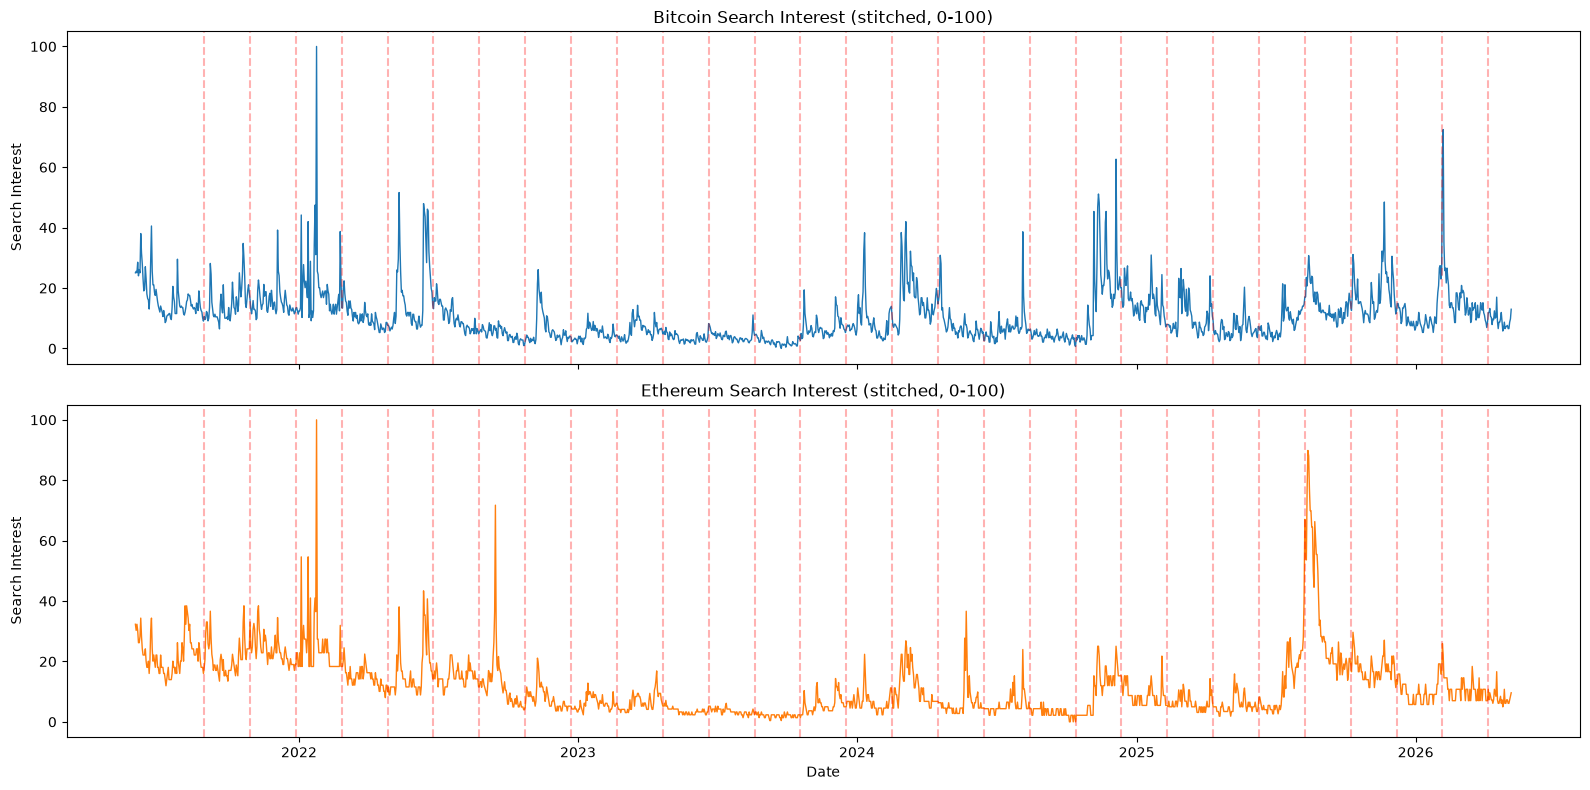

Checked 30 window boundaries (marked as red dashed lines).
Look closely at each red line — the series should flow smoothly through it,
with no sudden vertical jump or drop exactly at the line.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the stitched Google Trends data
df = pd.read_csv("../data/raw/google_trends.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

# Reconstruct the approximate window boundary dates
# (90-day windows, 30-day overlap -> new window starts every 60 days)
start_date = df["Date"].min()
end_date = df["Date"].max()

boundaries = []
cursor = start_date
while cursor < end_date:
    next_boundary = cursor + pd.Timedelta(days=90)
    boundaries.append(next_boundary)
    cursor = next_boundary - pd.Timedelta(days=30)

# --- Plot Bitcoin and Ethereum with boundary lines marked ---
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(df["Date"], df["Bitcoin"], color="tab:blue", linewidth=1)
axes[0].set_title("Bitcoin Search Interest (stitched, 0-100)")
axes[0].set_ylabel("Search Interest")

axes[1].plot(df["Date"], df["Ethereum"], color="tab:orange", linewidth=1)
axes[1].set_title("Ethereum Search Interest (stitched, 0-100)")
axes[1].set_ylabel("Search Interest")
axes[1].set_xlabel("Date")

# Draw a faint vertical line at each window boundary on both plots
for b in boundaries:
    if start_date < b < end_date:
        axes[0].axvline(b, color="red", linestyle="--", alpha=0.3)
        axes[1].axvline(b, color="red", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("../data/raw/google_trends_boundary_check.png", dpi=150)
plt.show()

print(f"Checked {len(boundaries)} window boundaries (marked as red dashed lines).")
print("Look closely at each red line — the series should flow smoothly through it,")
print("with no sudden vertical jump or drop exactly at the line.")

In [8]:
import pandas as pd
import requests

# Study period — must match the other three datasets (Bitcoin, Ethereum, Google Trends)
START_DATE = "2021-06-01"
END_DATE = "2026-05-06"

url = "https://api.alternative.me/fng/?limit=0&format=json"

response = requests.get(url)
response.raise_for_status()  # stop clearly if the request failed, instead of silently continuing

data = response.json()["data"]

fear_greed = pd.DataFrame(data)[["timestamp", "value", "value_classification"]].copy()

fear_greed.columns = ["Date", "Fear_Greed_Index", "Classification"]

# Convert timestamp text to number first, then to an actual date
fear_greed["Date"] = pd.to_numeric(fear_greed["Date"])
fear_greed["Date"] = pd.to_datetime(fear_greed["Date"], unit="s")

# Convert index value to number
fear_greed["Fear_Greed_Index"] = pd.to_numeric(fear_greed["Fear_Greed_Index"])

# Keep only the study period
fear_greed = fear_greed[
    (fear_greed["Date"] >= START_DATE) &
    (fear_greed["Date"] <= END_DATE)
]

fear_greed = fear_greed.sort_values("Date").reset_index(drop=True)

fear_greed.to_csv("../data/raw/fear_greed.csv", index=False)

print("Start Date:", fear_greed["Date"].min())
print("End Date:", fear_greed["Date"].max())
print("Total Days:", len(fear_greed))

Start Date: 2021-06-01 00:00:00
End Date: 2026-05-06 00:00:00
Total Days: 1800


In [9]:
full_range = pd.date_range("2021-06-01", "2026-05-06", freq="D")
missing = full_range.difference(fear_greed["Date"])
print("Missing date(s):", missing)


Missing date(s): DatetimeIndex(['2024-10-26'], dtype='datetime64[us]', freq='D')
